In [ ]:
from dataclasses import dataclass
from pathlib import Path
import math

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
from skimage.segmentation import watershed

Image : data/image2.jpg
Pièces détectées : 9
  Pièce 1 : diamètre environ 324 px, valeur estimée = 50
  Pièce 2 : diamètre environ 315 px, valeur estimée = 50
  Pièce 3 : diamètre environ 308 px, valeur estimée = 10
  Pièce 4 : diamètre environ 304 px, valeur estimée = 10
  Pièce 5 : diamètre environ 296 px, valeur estimée = 10
  Pièce 6 : diamètre environ 261 px, valeur estimée = 5
  Pièce 7 : diamètre environ 240 px, valeur estimée = 1
  Pièce 8 : diamètre environ 229 px, valeur estimée = 1
  Pièce 9 : diamètre environ 226 px, valeur estimée = 1
Total estimé : 138
Vérifiez les étiquettes sur l'image : le classement des tailles et les tailles manquantes sont des estimations.


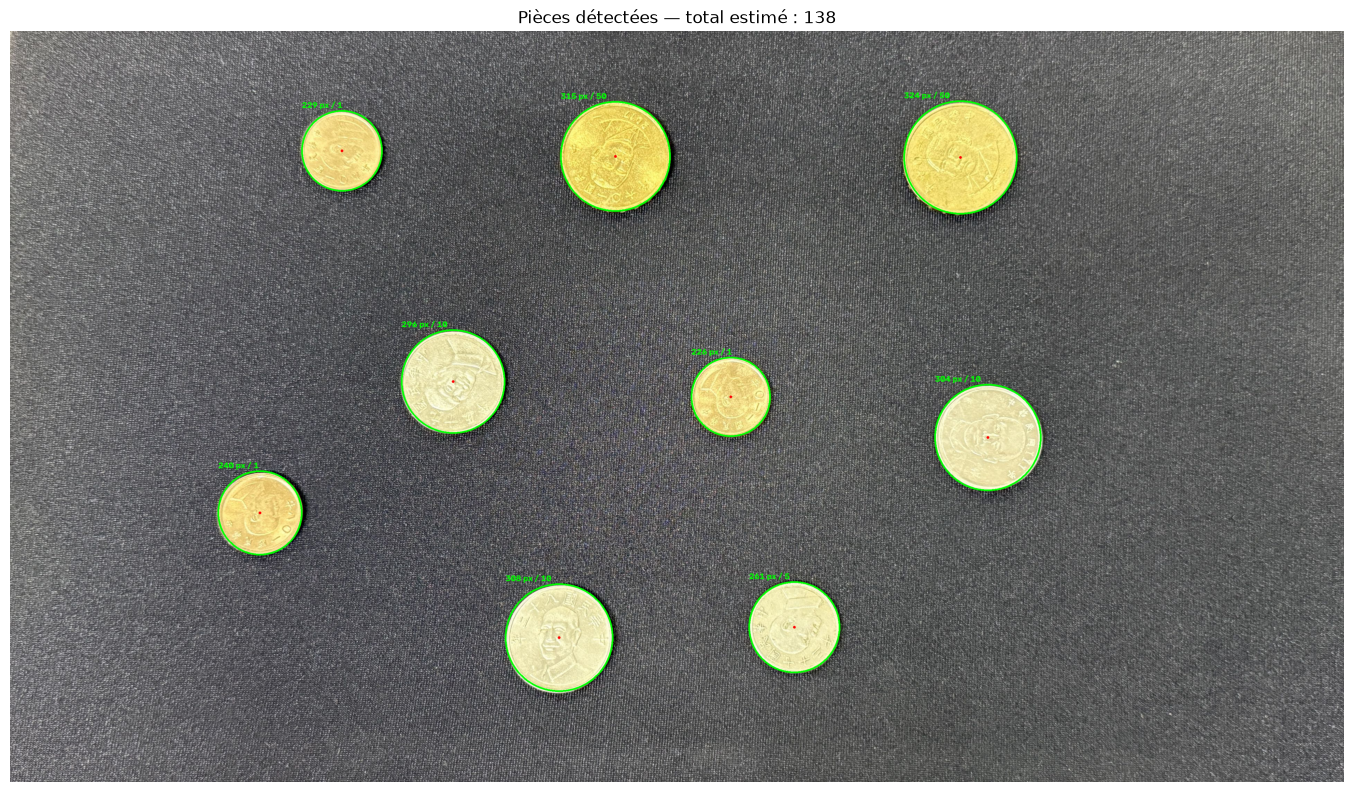

In [5]:
CHEMIN_IMAGE = "data/image2.jpg"

TAILLES_VALEURS = [50, 10, 5, 1]
TAILLE_MAX_IMAGE = 1400
TOLERANCE_REGROUPEMENT = 0.08
RAPPORT_TAILLE_MANQUANTE = 1.25


@dataclass
class Piece:
    x: int
    y: int
    diametre_px: float
    lab_b: float
    valeur: int | None = None


def mesurer_couleur_chaude(image: np.ndarray, x: int, y: int, diametre: float) -> float:
    """Mesure le jaune/doré au centre de la pièce, sans inclure son arrière-plan."""
    rayon = diametre / 2
    marge = max(1, round(rayon * 0.7))
    x_min, x_max = max(0, x - marge), min(image.shape[1], x + marge + 1)
    y_min, y_max = max(0, y - marge), min(image.shape[0], y + marge + 1)
    zone = image[y_min:y_max, x_min:x_max]

    lignes, colonnes = np.ogrid[y_min:y_max, x_min:x_max]
    distance = np.sqrt((colonnes - x) ** 2 + (lignes - y) ** 2)
    masque = (distance >= rayon * 0.2) & (distance <= rayon * 0.68)
    lab = cv2.cvtColor(zone, cv2.COLOR_BGR2LAB)
    return float(np.median(lab[:, :, 2][masque]))


def detecter_pieces(image: np.ndarray) -> list[Piece]:
    """Repère les cercles et renvoie leur centre et leur diamètre en pixels."""
    hauteur, largeur = image.shape[:2]
    facteur = min(1.0, TAILLE_MAX_IMAGE / max(hauteur, largeur))

    if facteur < 1:
        image_reduite = cv2.resize(
            image, None, fx=facteur, fy=facteur, interpolation=cv2.INTER_AREA
        )
    else:
        image_reduite = image

    gris = cv2.cvtColor(image_reduite, cv2.COLOR_BGR2GRAY)
    flou = cv2.medianBlur(gris, 5)
    cote_court = min(flou.shape)

    bordure = np.concatenate((flou[0, :], flou[-1, :], flou[:, 0], flou[:, -1]))
    if float(np.median(bordure)) < 128:
        _, masque = cv2.threshold(
            gris, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )
        noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        masque = cv2.morphologyEx(masque, cv2.MORPH_CLOSE, noyau)
        masque = cv2.morphologyEx(masque, cv2.MORPH_OPEN, noyau)

        rayon_min = max(6, int(cote_court * 0.02))
        rayon_max = max(12, int(cote_court * 0.12))
        aire_min = math.pi * rayon_min**2 * 1.25
        aire_max = math.pi * rayon_max**2 * 1.6
        distance = cv2.distanceTransform(masque, cv2.DIST_L2, 5)
        taille_fenetre = max(15, int(cote_court * 0.04))
        maximum_distance = max(10, cote_court * 0.025)
        maxima = (
            (distance == ndimage.maximum_filter(distance, size=taille_fenetre))
            & (distance > maximum_distance)
            & (masque > 0)
        )
        etiquettes_maxima, nombre_maxima = ndimage.label(maxima)
        candidats: list[tuple[float, int, int]] = []

        for indice in range(1, nombre_maxima + 1):
            ys, xs = np.where(etiquettes_maxima == indice)
            if len(xs):
                position = int(np.argmax(distance[ys, xs]))
                candidats.append(
                    (
                        float(distance[ys[position], xs[position]]),
                        int(xs[position]),
                        int(ys[position]),
                    )
                )

        candidats.sort(reverse=True)
        distance_minimale = max(18, int(cote_court * 0.045))
        centres_pieces: list[tuple[float, int, int]] = []
        for candidat in candidats:
            _, x, y = candidat
            trop_proche = any(
                math.hypot(x - autre_x, y - autre_y) < distance_minimale
                for _, autre_x, autre_y in centres_pieces
            )
            if not trop_proche:
                centres_pieces.append(candidat)

        marqueurs = np.zeros(masque.shape, dtype=np.int32)
        for indice, (_, x, y) in enumerate(centres_pieces, start=1):
            marqueurs[y, x] = indice

        regions = watershed(-distance, marqueurs, mask=masque > 0)
        pieces_segmentees: list[Piece] = []

        for indice, (_, x, y) in enumerate(centres_pieces, start=1):
            aire = int(np.count_nonzero(regions == indice))
            if aire_min <= aire <= aire_max:
                pieces_segmentees.append(
                    Piece(
                        x=round(x / facteur),
                        y=round(y / facteur),
                        diametre_px=2 * math.sqrt(aire / math.pi) / facteur,
                        lab_b=0,
                    )
                )

        if pieces_segmentees:
            for piece in pieces_segmentees:
                piece.lab_b = mesurer_couleur_chaude(
                    image, piece.x, piece.y, piece.diametre_px
                )
            return pieces_segmentees

    if cote_court < 600:
        seuil_hough = 38
        rayon_min = max(6, int(cote_court * 0.015))
        rayon_max = max(12, int(cote_court * 0.12))
    else:
        seuil_hough = 45
        rayon_min = max(6, int(cote_court * 0.02))
        rayon_max = max(12, int(cote_court * 0.10))

    cercles = cv2.HoughCircles(
        flou,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=max(15, int(cote_court * 0.04)),
        param1=140,
        param2=seuil_hough,
        minRadius=rayon_min,
        maxRadius=rayon_max,
    )

    if cercles is None:
        return []

    pieces: list[Piece] = []
    for x, y, rayon in cercles[0]:
        piece = Piece(
            x=round(x / facteur),
            y=round(y / facteur),
            diametre_px=2 * rayon / facteur,
            lab_b=0,
        )

        # Hough peut proposer plusieurs cercles presque concentriques pour une pièce.
        doublon = any(
            math.hypot(piece.x - autre.x, piece.y - autre.y)
            < min(piece.diametre_px, autre.diametre_px) * 0.22
            and abs(piece.diametre_px - autre.diametre_px)
            / max(piece.diametre_px, autre.diametre_px)
            < 0.25
            for autre in pieces
        )
        if not doublon:
            pieces.append(piece)

    for piece in pieces:
        piece.lab_b = mesurer_couleur_chaude(
            image, piece.x, piece.y, piece.diametre_px
        )

    return pieces


def regrouper_par_taille(pieces: list[Piece]) -> list[list[Piece]]:
    """Rassemble les diamètres proches en groupes, du plus petit au plus grand."""
    groupes: list[list[Piece]] = []

    for piece in sorted(pieces, key=lambda p: p.diametre_px):
        if not groupes:
            groupes.append([piece])
            continue

        diametre_median = float(
            np.median([membre.diametre_px for membre in groupes[-1]])
        )
        ecart_relatif = abs(piece.diametre_px - diametre_median) / diametre_median
        if ecart_relatif <= TOLERANCE_REGROUPEMENT:
            groupes[-1].append(piece)
        else:
            groupes.append([piece])

    return groupes


def attribuer_valeurs(groupes: list[list[Piece]]) -> None:
    """Utilise la couleur pour séparer les 50 des 10, puis compare les diamètres."""
    pieces = [piece for groupe in groupes for piece in groupe]
    plus_grand_diametre = max(piece.diametre_px for piece in pieces)
    grandes_pieces = [
        piece
        for piece in pieces
        if piece.diametre_px >= plus_grand_diametre * 0.9
    ]

    pieces_de_50: list[Piece] = []
    if len(grandes_pieces) >= 3:
        couleurs = sorted(piece.lab_b for piece in grandes_pieces)
        ecarts = [
            (couleurs[i + 1] - couleurs[i], i)
            for i in range(len(couleurs) - 1)
        ]
        ecart_max, position_ecart = max(ecarts)

        # Sur ces pièces, une surface dorée distingue les 50 des 10 argentées.
        if ecart_max >= 12:
            seuil_couleur = (
                couleurs[position_ecart] + couleurs[position_ecart + 1]
            ) / 2
            pieces_de_50 = [
                piece
                for piece in grandes_pieces
                if piece.lab_b > seuil_couleur
            ]

    for piece in pieces_de_50:
        piece.valeur = 50

    pieces_a_classer = [piece for piece in pieces if piece not in pieces_de_50]
    groupes_a_classer = regrouper_par_taille(pieces_a_classer)
    groupes_grands_vers_petits = list(reversed(groupes_a_classer))

    # Si les 50 ont été séparées par couleur, les autres tailles commencent à 10.
    indice_valeur = 1 if pieces_de_50 else 0

    for position, groupe in enumerate(groupes_grands_vers_petits):
        if position:
            diametre_precedent = float(
                np.median(
                    [piece.diametre_px for piece in groupes_grands_vers_petits[position - 1]]
                )
            )
            diametre_actuel = float(
                np.median([piece.diametre_px for piece in groupe])
            )
            rapport = diametre_precedent / diametre_actuel

            # Un grand écart peut signaler une ou plusieurs tailles absentes.
            if rapport > RAPPORT_TAILLE_MANQUANTE:
                pas = 2 + int(
                    math.log(
                        rapport / RAPPORT_TAILLE_MANQUANTE,
                        RAPPORT_TAILLE_MANQUANTE,
                    )
                )
            else:
                pas = 1
            indice_valeur += pas

            # Avec quatre groupes ou moins, la plus petite classe ne peut pas
            # être plus petite que la quatrième valeur prévue.
            if len(groupes) <= len(TAILLES_VALEURS):
                indice_valeur = min(indice_valeur, len(TAILLES_VALEURS) - 1)

        valeur = (
            TAILLES_VALEURS[indice_valeur]
            if indice_valeur < len(TAILLES_VALEURS)
            else None
        )
        for piece in groupe:
            piece.valeur = valeur


def main() -> None:
    image = cv2.imread(str(CHEMIN_IMAGE))
    if image is None:
        raise FileNotFoundError(f"Image introuvable ou illisible : {CHEMIN_IMAGE}")

    pieces = detecter_pieces(image)
    if not pieces:
        print("Aucune pièce détectée. Vérifiez l'image et les paramètres de détection.")
        return

    groupes = regrouper_par_taille(pieces)
    attribuer_valeurs(groupes)

    total = sum(piece.valeur or 0 for piece in pieces)
    inconnues = sum(piece.valeur is None for piece in pieces)

    print(f"Image : {CHEMIN_IMAGE}")
    print(f"Pièces détectées : {len(pieces)}")
    for numero, piece in enumerate(pieces, start=1):
        valeur = "indéterminée" if piece.valeur is None else str(piece.valeur)
        print(
            f"  Pièce {numero} : diamètre environ {piece.diametre_px:.0f} px, "
            f"valeur estimée = {valeur}"
        )
    print(f"Total estimé : {total}")

    if inconnues:
        print(
            f"Attention : {inconnues} pièce(s) n'ont pas pu être classées "
            "et ne sont pas incluses dans le total."
        )
    print(
        "Vérifiez les étiquettes sur l'image : le classement des tailles "
        "et les tailles manquantes sont des estimations."
    )

    image_annotee = image.copy()
    for piece in pieces:
        centre = (piece.x, piece.y)
        rayon = round(piece.diametre_px / 2)
        cv2.circle(image_annotee, centre, rayon, (0, 255, 0), 4)
        cv2.circle(image_annotee, centre, 4, (0, 0, 255), -1)
        etiquette = "?" if piece.valeur is None else str(piece.valeur)
        cv2.putText(
            image_annotee,
            f"{round(piece.diametre_px)} px / {etiquette}",
            (piece.x - rayon, piece.y - rayon - 8),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2,
            cv2.LINE_AA,
        )

    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(image_annotee, cv2.COLOR_BGR2RGB))
    plt.title(f"Pièces détectées — total estimé : {total}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()
